In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')

In [ ]:
df = pd.read_csv("Airline_dataset.csv")

df.head()

,Unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


In [ ]:
df.shape

(300153, 12)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300153 entries, 0 to 300152
Data columns (total 12 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        300153 non-null  int64  
 1   airline           300153 non-null  object 
 2   flight            300153 non-null  object 
 3   source_city       300153 non-null  object 
 4   departure_time    300153 non-null  object 
 5   stops             300153 non-null  object 
 6   arrival_time      300153 non-null  object 
 7   destination_city  300153 non-null  object 
 8   class             300153 non-null  object 
 9   duration          300153 non-null  float64
 10  days_left         300153 non-null  int64  
 11  price             300153 non-null  int64  
dtypes: float64(1), int64(3), object(8)
memory usage: 27.5+ MB


In [ ]:
df.columns

Index(['Unnamed: 0', 'airline', 'flight', 'source_city', 'departure_time',
       'stops', 'arrival_time', 'destination_city', 'class', 'duration',
       'days_left', 'price'],
      dtype='object')

In [ ]:
df.isnull().sum()

,0
Unnamed: 0,0
airline,0
flight,0
source_city,0
departure_time,0
stops,0
arrival_time,0
destination_city,0
class,0
duration,0


In [ ]:
df.describe()

,Unnamed: 0,duration,days_left,price
count,300153.000000,300153.000000,300153.000000,300153.000000
mean,150076.000000,12.221021,26.004751,20889.660523
std,86646.852011,7.191997,13.561004,22697.767366
min,0.000000,0.830000,1.000000,1105.000000
25%,75038.000000,6.830000,15.000000,4783.000000
50%,150076.000000,11.250000,26.000000,7425.000000
75%,225114.000000,16.170000,38.000000,42521.000000
max,300152.000000,49.830000,49.000000,123071.000000


In [ ]:
df.duplicated().sum()

np.int64(0)

# Data Cleaning


In [ ]:
df.columns = df.columns.str.strip().str.lower()

df.head()

,unnamed: 0,airline,flight,source_city,departure_time,stops,arrival_time,destination_city,class,duration,days_left,price
0,0,SpiceJet,SG-8709,Delhi,Evening,zero,Night,Mumbai,Economy,2.17,1,5953
1,1,SpiceJet,SG-8157,Delhi,Early_Morning,zero,Morning,Mumbai,Economy,2.33,1,5953
2,2,AirAsia,I5-764,Delhi,Early_Morning,zero,Early_Morning,Mumbai,Economy,2.17,1,5956
3,3,Vistara,UK-995,Delhi,Morning,zero,Afternoon,Mumbai,Economy,2.25,1,5955
4,4,Vistara,UK-963,Delhi,Morning,zero,Morning,Mumbai,Economy,2.33,1,5955


In [ ]:
df = df.loc[:, ~df.columns.str.contains('^unnamed')]

In [ ]:
df.isnull().sum()

,0
airline,0
flight,0
source_city,0
departure_time,0
stops,0
arrival_time,0
destination_city,0
class,0
duration,0
days_left,0


In [ ]:
df = df.drop_duplicates()

df.shape

(300153, 11)

In [ ]:
df.dtypes

,0
airline,object
flight,object
source_city,object
departure_time,object
stops,object
arrival_time,object
destination_city,object
class,object
duration,float64
days_left,int64


In [ ]:
df['price'] = pd.to_numeric(df['price'], errors='coerce')

# Exploratory Data Analysis (EDA)

In [ ]:
print("Total Flight Records:", len(df))

Total Flight Records: 300153


In [ ]:
print("Total Airlines:", df['airline'].nunique())

Total Airlines: 6


In [ ]:
print("Average Ticket Price:", df['price'].mean())

Average Ticket Price: 20889.660523133203


In [ ]:
print("Maximum Ticket Price:", df['price'].max())

Maximum Ticket Price: 123071


In [ ]:
print("Minimum Ticket Price:", df['price'].min())

Minimum Ticket Price: 1105


In [ ]:
airline_price = df.groupby('airline')['price'].mean().sort_values(ascending=False)

print(airline_price)

airline
Vistara      30396.536302
Air_India    23507.019112
SpiceJet      6179.278881
GO_FIRST      5652.007595
Indigo        5324.216303
AirAsia       4091.072742
Name: price, dtype: float64


In [ ]:
airline_count = df['airline'].value_counts()

print(airline_count)

airline
Vistara      127859
Air_India     80892
Indigo        43120
GO_FIRST      23173
AirAsia       16098
SpiceJet       9011
Name: count, dtype: int64


In [ ]:
class_price = df.groupby('class')['price'].mean()

print(class_price)

class
Business    52540.081124
Economy      6572.342383
Name: price, dtype: float64


In [ ]:
route_price = df.groupby(['source_city', 'destination_city'])['price'].mean().sort_values(ascending=False)

print(route_price.head(10))

source_city  destination_city
Chennai      Bangalore           25081.850454
Kolkata      Chennai             23660.361040
Bangalore    Kolkata             23500.061229
             Chennai             23321.850078
Mumbai       Bangalore           23147.873807
Bangalore    Mumbai              23128.618672
Mumbai       Chennai             22781.899112
Chennai      Mumbai              22765.849647
Kolkata      Bangalore           22744.808428
Chennai      Kolkata             22669.932407
Name: price, dtype: float64


In [ ]:
stops_price = df.groupby('stops')['price'].mean()

print(stops_price)

stops
one            22900.992482
two_or_more    14113.450775
zero            9375.938535
Name: price, dtype: float64


# Data Visualization

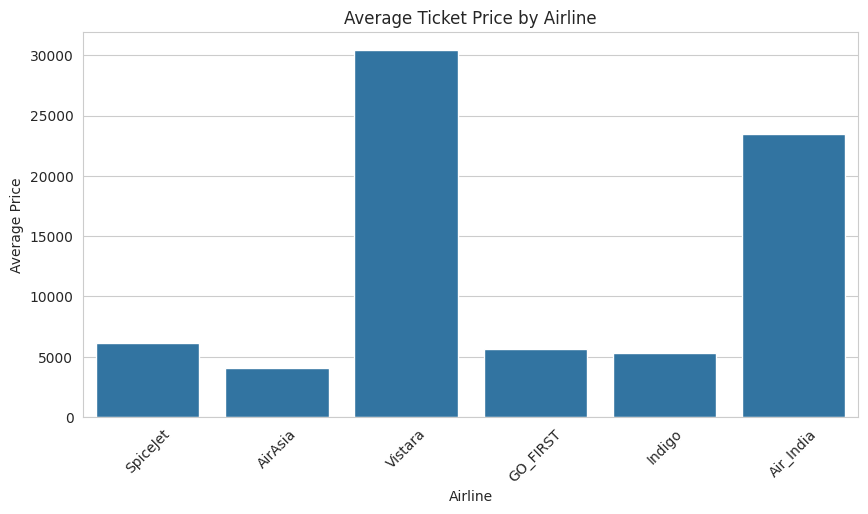

In [ ]:
plt.figure(figsize=(10,5))

sns.barplot(data=df, x='airline', y='price', errorbar=None)

plt.title('Average Ticket Price by Airline')
plt.xlabel('Airline')
plt.ylabel('Average Price')
plt.xticks(rotation=45)

plt.show()

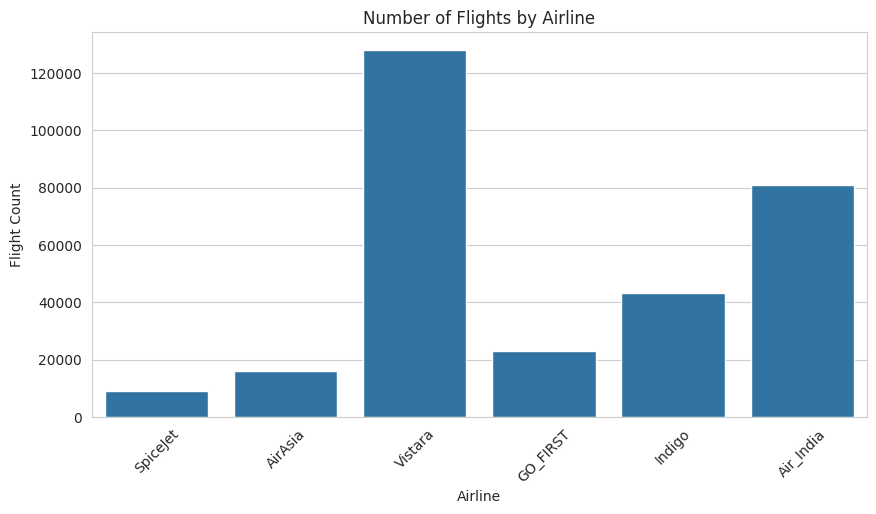

In [ ]:
plt.figure(figsize=(10,5))

sns.countplot(data=df, x='airline')

plt.title('Number of Flights by Airline')
plt.xlabel('Airline')
plt.ylabel('Flight Count')
plt.xticks(rotation=45)

plt.show()

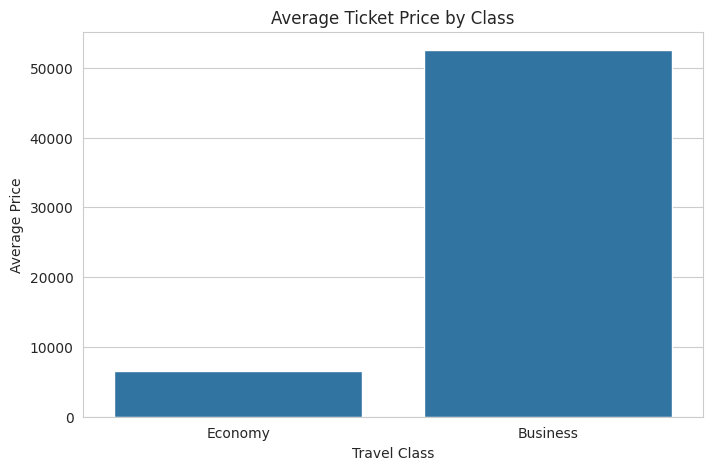

In [ ]:
plt.figure(figsize=(8,5))

sns.barplot(data=df, x='class', y='price', errorbar=None)

plt.title('Average Ticket Price by Class')
plt.xlabel('Travel Class')
plt.ylabel('Average Price')

plt.show()

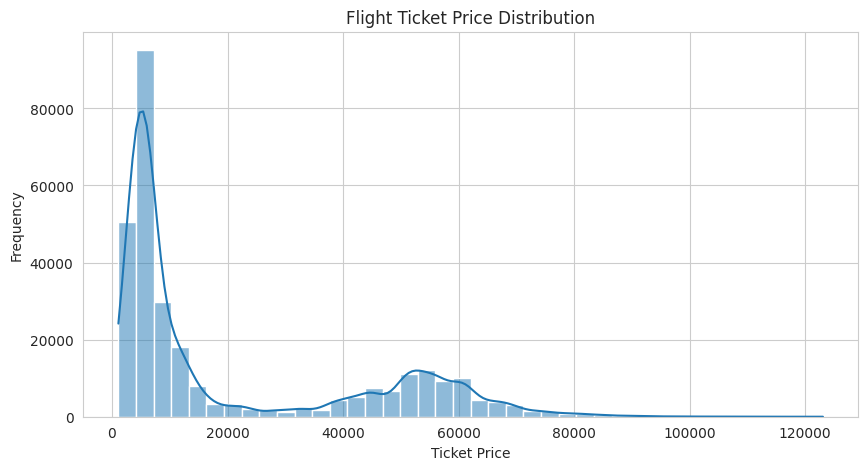

In [ ]:
plt.figure(figsize=(10,5))

sns.histplot(df['price'], bins=40, kde=True)

plt.title('Flight Ticket Price Distribution')
plt.xlabel('Ticket Price')
plt.ylabel('Frequency')

plt.show()

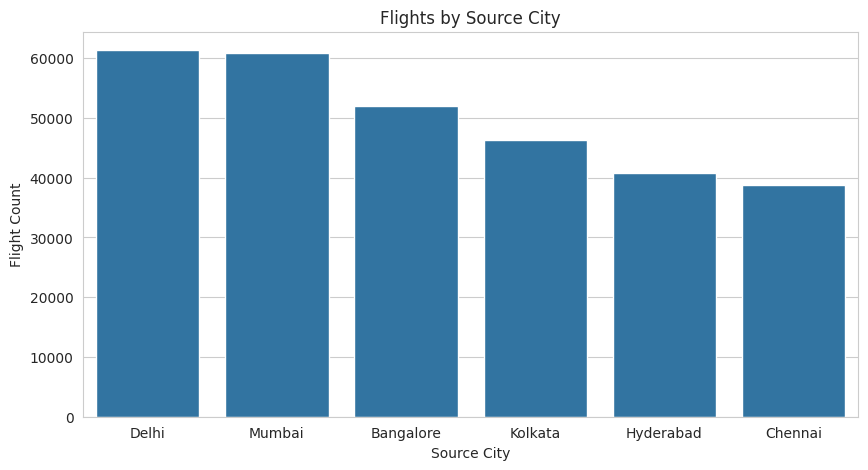

In [ ]:
plt.figure(figsize=(10,5))

sns.countplot(data=df, x='source_city')

plt.title('Flights by Source City')
plt.xlabel('Source City')
plt.ylabel('Flight Count')

plt.show()

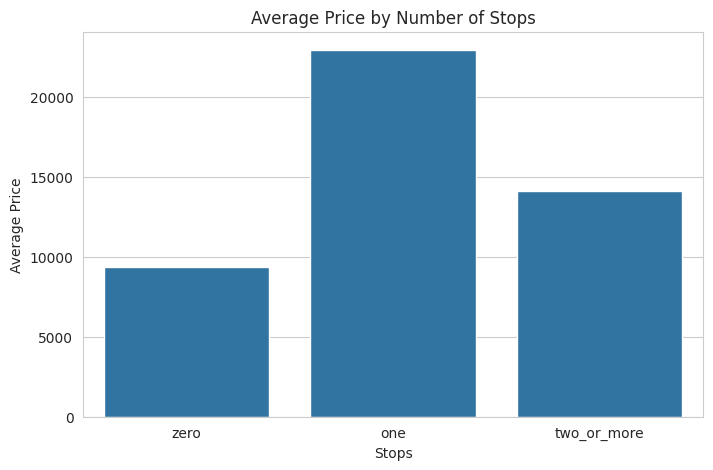

In [ ]:
plt.figure(figsize=(8,5))

sns.barplot(data=df, x='stops', y='price', errorbar=None)

plt.title('Average Price by Number of Stops')
plt.xlabel('Stops')
plt.ylabel('Average Price')

plt.show()

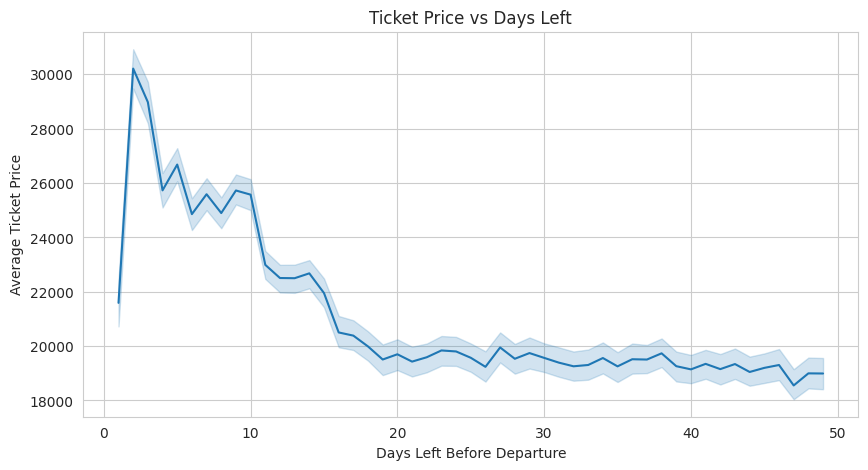

In [ ]:
plt.figure(figsize=(10,5))

sns.lineplot(data=df, x='days_left', y='price')

plt.title('Ticket Price vs Days Left')
plt.xlabel('Days Left Before Departure')
plt.ylabel('Average Ticket Price')

plt.show()

# Correlation Analysis

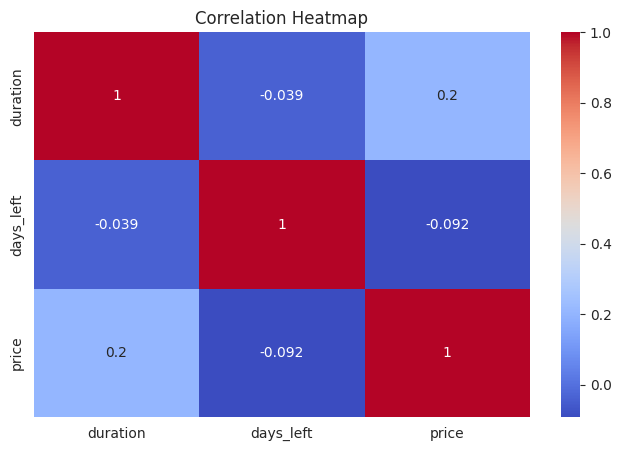

In [ ]:
plt.figure(figsize=(8,5))

numeric_df = df.select_dtypes(include=np.number)

sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm')

plt.title('Correlation Heatmap')

plt.show()

In [ ]:
print("AIRLINE DATA ANALYSIS INSIGHTS")

print("\n1. Highest Average Ticket Price Airline:")
print(airline_price.idxmax())

print("\n2. Lowest Average Ticket Price Airline:")
print(airline_price.idxmin())

print("\n3. Most Available Airline:")
print(airline_count.idxmax())

print("\n4. Most Expensive Travel Class:")
print(class_price.idxmax())

print("\n5. Most Expensive Route:")
print(route_price.index[0])

AIRLINE DATA ANALYSIS INSIGHTS

1. Highest Average Ticket Price Airline:
Vistara

2. Lowest Average Ticket Price Airline:
AirAsia

3. Most Available Airline:
Vistara

4. Most Expensive Travel Class:
Business

5. Most Expensive Route:
('Chennai', 'Bangalore')


In [ ]:
df.to_csv("Airline_Cleaned_Data.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!
